# Notebook 5 — Variance Risk Premium & Volatility Trading

**This notebook's job:** move from forecasting to derivatives and test the remaining three hypotheses.

| | Hypothesis | Test |
|---|---|---|
| **H3** | The forecast carries information about future variance **beyond** implied variance | Encompassing regression: log RV on log IV² and log forecast, HAC |
| **H4** | The variance risk premium is predictable out of sample | R²<sub>OOS</sub> of IV² − forecast vs the historical-mean VRP |
| **H5** | A forecast-timed volatility strategy earns positive risk-adjusted returns after costs | Variance-swap proxy, validation-selected, tested once; PSR and Deflated Sharpe |

**Implied variance used**

| Horizon | Implied measure | Why |
|---|---|---|
| *h* = 20 | VIX² | VIX covers 30 calendar days ≈ 21 trading days. This is the primary horizon |
| *h* = 5 | VIX9D² | Covers 9 calendar days ≈ 6 trading days |

**How H5 is tested, and what the caveat is.** The trading test uses a **variance-swap proxy**: short or long one unit of 20-day variance struck at VIX², with P&L in vol points per unit of vega notional. This is the standard way to measure the volatility risk premium in academic work, but it is a *proxy*:
- VIX is computed from SPX options, not SPY options.
- It ignores the variance-swap convexity and jump adjustment.
- Costs are an assumption, tested across a range.

**The executable test needs historical SPY option quotes.** Part E runs a delta-hedged straddle backtest on real bid/ask quotes as soon as a chain file is supplied. It never substitutes model prices for missing quotes.

**Discipline:**
- Descriptive VRP statistics use 2015–2022 only.
- Strategy settings come from `config.yaml`, fixed before this notebook was written.
- Selection uses the validation years 2019–2022, and the selected strategy is frozen and hashed.
- The test period 2023–2025 is run **once**.

## 0. Setup

In [1]:
import os, sys, json, hashlib, itertools, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy import stats
from statsmodels.tsa.stattools import acf

from src.config import load_config
from src.data import acquire
from src import strategy as S
from src import evaluation as E
from src import options_bt as O

cfg, P = load_config(ROOT)
SC = cfg["strategy"]
HS = SC["horizon"]
SEED = cfg["project"]["seed"]
DATA_MODE = os.environ.get("VOLRES_DATA_MODE", "live")
sub = "_synthetic" if DATA_MODE == "synthetic" else ""
OUT = P.processed / sub if sub else P.processed
FIG = P.figures / sub if sub else P.figures
RES = P.results / sub if sub else P.results
for p in (FIG, RES):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(FIG / f"nb05_{name}.png", bbox_inches="tight", dpi=150)

if DATA_MODE == "synthetic":
    print("=" * 72 + "\nSYNTHETIC MODE: pipeline test only. These numbers are NOT research results.\n" + "=" * 72)

## 1. Load inputs and verify provenance

In [2]:
meta1 = json.loads((OUT / "nb01_meta.json").read_text())
meta3 = json.loads((OUT / "nb03_meta.json").read_text())
meta4 = json.loads((OUT / "nb04_meta.json").read_text())
assert acquire.sha256(OUT / "oos_forecasts.parquet") == meta3["outputs_sha256"]["oos_forecasts.parquet"]
assert acquire.sha256(OUT / "ensembles.parquet") == meta4["outputs_sha256"]["ensembles.parquet"]
assert acquire.sha256(OUT / "panel.parquet") == meta1["outputs_sha256"]["panel.parquet"]

panel = pd.read_parquet(OUT / "panel.parquet")
targets = pd.read_parquet(OUT / "targets.parquet")
X = pd.read_parquet(OUT / "features.parquet")
fc = pd.read_parquet(OUT / "oos_forecasts.parquet")
ens = pd.read_parquet(OUT / "ensembles.parquet")
regimes = pd.read_parquet(OUT / "regimes.parquet").drop_duplicates("date").set_index("date")["regime"]

IVCOL = {20: "vix_var", 5: "vix9d_var"}
H = [h for h in (20, 5) if IVCOL[h] in panel]
W, SPLIT = {}, {}
for h in H:
    w = fc[fc.horizon == h].pivot(index="date", columns="model", values="forecast").sort_index()
    e = ens.xs(h, level="horizon")
    W[h] = w.join(e)
    SPLIT[h] = fc[fc.horizon == h].drop_duplicates("date").set_index("date")["split"].reindex(W[h].index)
TEST_START, SAMPLE_END = pd.Timestamp(cfg["splits"]["test_start"]), pd.Timestamp(cfg["data"]["sample_end"])
print({h: (W[h].index.min().date(), W[h].index.max().date(), IVCOL[h]) for h in H})

{20: (datetime.date(2019, 1, 2), datetime.date(2025, 12, 31), 'vix_var'), 5: (datetime.date(2019, 1, 2), datetime.date(2025, 12, 31), 'vix9d_var')}


## Part A — The variance risk premium (descriptive, development period 2015–2022)

$$VRP_{t,h} = IV^2_t - RV_{t,h}$$

This is in annualised variance, with IV² taken from VIX² or VIX9D² and RV the realised variance over *t+1…t+h*. It is shown alongside the volatility spread IV − √RV in vol points, which is easier to read.

- A positive mean means option buyers pay for variance protection on average. That is the premium a volatility seller earns for bearing crash risk.
- It is **measured after the fact**: RV is unknown at *t*. Parts B–D ask whether any of it can be anticipated.

In [3]:
DEV = (panel.index >= cfg["data"]["sample_start"]) & (panel.index < TEST_START)
vrp, vrp_vol = {}, {}
for h in H:
    iv = panel[IVCOL[h]]
    vrp[h] = (iv - targets[f"rv_var_{h}"]).rename(f"VRP_{h}")
    vrp_vol[h] = (np.sqrt(iv) - targets[f"rv_vol_{h}"]).rename(f"VolSpread_{h}")

rows = []
for h in H:
    v, vv = vrp[h][DEV].dropna(), vrp_vol[h][DEV].dropna()
    t_nw = v.mean() / np.sqrt(E.nw_variance(v.to_numpy(), 3 * h))
    rows.append({"horizon": h, "implied": IVCOL[h], "mean VRP (var)": v.mean(), "median VRP (var)": v.median(),
                 "t-stat (HAC 3h)": t_nw, "share positive": (v > 0).mean(),
                 "mean IV - RV (vol pts)": 100 * vv.mean(), "median IV - RV (vol pts)": 100 * vv.median(),
                 "5% worst (vol pts)": 100 * vv.quantile(0.05), "skew": stats.skew(v),
                 "acf at lag h": acf(v, nlags=2 * h, fft=True)[h], "acf at lag 2h": acf(v, nlags=2 * h, fft=True)[2 * h]})
vrp_summary = pd.DataFrame(rows).set_index("horizon")
vrp_summary.T

horizon,20,5
implied,vix_var,vix9d_var
mean VRP (var),0.006521,0.006888
median VRP (var),0.01106,0.009744
t-stat (HAC 3h),1.062,1.831
share positive,0.8118,0.8158
mean IV - RV (vol pts),3.432,3.623
median IV - RV (vol pts),4.609,4.572
5% worst (vol pts),-8.222,-7.636
skew,-7.519,-11.18
acf at lag h,-0.06732,0.09499


,mean (vol pts),median (vol pts),share positive
date,,,
2015,1.982,3.116,0.7976
2016,4.571,5.317,0.8611
2017,4.287,4.352,0.996
2018,0.8206,3.648,0.6255
2019,4.164,4.971,0.8373
2020,2.822,9.122,0.7708
2021,6.965,7.08,0.9563
2022,1.837,2.168,0.6494


,VIX range,mean IV−RV (vol pts),share positive,5% worst (vol pts)
vix_var,,,,
Q1,9–13,2.334,0.8387,-11.03
Q2,13–15,1.728,0.804,-12.81
Q3,15–19,3.487,0.802,-6.409
Q4,19–24,4.128,0.7805,-6.665
Q5,24–83,5.488,0.8337,-4.759


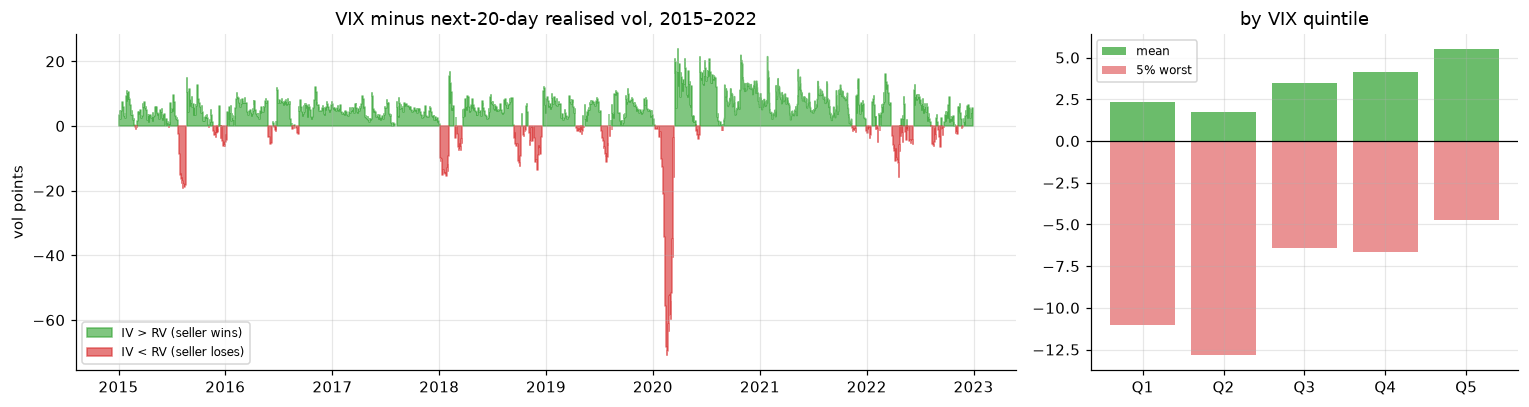

In [4]:
h = HS
v = vrp_vol[h][DEV]
vix = np.sqrt(panel.loc[DEV, IVCOL[h]]) * 100
by_year = (100 * v).groupby(v.index.year).agg(["mean", "median", lambda x: (x > 0).mean()])
by_year.columns = ["mean (vol pts)", "median (vol pts)", "share positive"]
q = pd.qcut(vix, 5, labels=[f"Q{i}" for i in range(1, 6)])
by_vix = pd.DataFrame({"VIX range": vix.groupby(q).agg(lambda x: f"{x.min():.0f}–{x.max():.0f}"),
                       "mean IV−RV (vol pts)": (100 * v).groupby(q).mean(),
                       "share positive": (v > 0).groupby(q).mean(),
                       "5% worst (vol pts)": (100 * v).groupby(q).quantile(0.05)})
display(by_year)
display(by_vix)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
vv = 100 * vrp_vol[h][DEV]
ax[0].fill_between(vv.index, 0, vv, where=vv >= 0, color="tab:green", alpha=0.6, step="mid", label="IV > RV (seller wins)")
ax[0].fill_between(vv.index, 0, vv, where=vv < 0, color="tab:red", alpha=0.6, step="mid", label="IV < RV (seller loses)")
ax[0].set_ylabel("vol points"); ax[0].legend(fontsize=8); ax[0].set_title(f"VIX minus next-{h}-day realised vol, 2015–2022")
ax[1].bar(by_vix.index, by_vix["mean IV−RV (vol pts)"], color="tab:green", alpha=0.7, label="mean")
ax[1].bar(by_vix.index, by_vix["5% worst (vol pts)"], color="tab:red", alpha=0.5, label="5% worst")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_title("by VIX quintile"); ax[1].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "vrp_dev"); plt.show()

**Reading Part A.**
- The premium is usually positive and usually small, with a fat left tail. That is the "picking up pennies in front of a steamroller" profile.
- **Persistence (the ACF at lag *h*) is what makes timing conceivable at all.** If high-premium periods cluster, a signal observed at *t* may say something about the premium earned over *t+1…t+h*.
- The VIX-quintile table shows whether the premium is larger when VIX is high (compensation for risk) or when it is low (complacency).

## Part B — H3: does the forecast know something the option market does not?

$$\log RV_{t,h} = a + b_{IV}\log IV^2_t + b_F \log \hat\sigma^2_{t,h} + \varepsilon$$

- If **b<sub>F</sub> > 0** significantly, the forecast contains information about future variance that implied variance does not already reflect. That is a necessary condition for a forecast-based volatility trade to work.
- The **spread regression** asks the trading question directly: does log(forecast / IV²) predict log(RV / IV²)?

Both regressions use HAC standard errors with 3*h* lags. Several models are tested, so p-values are Holm-adjusted across them. XGB is the pre-specified primary model.

In [5]:
H3_MODELS = ["XGB", "HAR_X", "ENS_EQ", "GJR", "HAR"]
h3_rows = []
for h in H:
    for split in ("test", "val"):
        m = (SPLIT[h] == split)
        d = W[h].index[m]
        rv, iv = targets.loc[d, f"rv_var_{h}"], panel.loc[d, IVCOL[h]]
        ok = iv.notna()
        for mdl in H3_MODELS:
            r = S.encompassing_regression(rv[ok], iv[ok], W[h].loc[d[ok], mdl], h)
            sr = S.spread_regression(rv[ok], iv[ok], W[h].loc[d[ok], mdl], h)
            h3_rows.append({"horizon": h, "split": split, "model": mdl, **r, "spread_b": sr["b"], "spread_t": sr["t_b"],
                            "spread_p": sr["p_b"], "spread_R2": sr["R2"]})
h3 = pd.DataFrame(h3_rows)
from statsmodels.stats.multitest import multipletests
h3["p_f_holm"] = np.nan
for (h, split), g in h3.groupby(["horizon", "split"]):
    h3.loc[g.index, "p_f_holm"] = multipletests(g["p_f"], method="holm")[1]
cols = ["b_iv", "t_iv", "b_f", "t_f", "p_f", "p_f_holm", "R2_iv_only", "R2_both", "spread_b", "spread_p"]
for h in H:
    print(f"\n=== h = {h}, TEST (2023–2025) ===")
    display(h3[(h3.horizon == h) & (h3.split == "test")].set_index("model")[cols])


=== h = 20, TEST (2023–2025) ===


,b_iv,t_iv,b_f,t_f,p_f,p_f_holm,R2_iv_only,R2_both,spread_b,spread_p
model,,,,,,,,,,
XGB,0.4623,2.56,0.4038,3.288,0.001009,0.004038,0.2538,0.2956,0.4155,0.000647
HAR_X,0.7056,0.5903,0.1264,0.1011,0.9194,0.9194,0.2538,0.2539,-0.2777,0.8399
ENS_EQ,-0.2802,-0.9488,1.076,3.825,0.0001307,0.0006536,0.2538,0.3233,1.026,6.751e-05
GJR,0.3915,1.847,0.3966,2.234,0.0255,0.07651,0.2538,0.2872,0.3505,0.02865
HAR,0.7416,5.116,0.1338,0.8126,0.4164,0.8329,0.2538,0.2571,0.1902,0.07383



=== h = 5, TEST (2023–2025) ===


,b_iv,t_iv,b_f,t_f,p_f,p_f_holm,R2_iv_only,R2_both,spread_b,spread_p
model,,,,,,,,,,
XGB,0.3742,1.759,0.5508,3.919,8.905e-05,0.0004453,0.3722,0.3957,0.4852,0.0004545
HAR_X,1.622,6.197,-0.5116,-2.418,0.01561,0.06245,0.3722,0.3853,-0.4701,0.02868
ENS_EQ,0.7204,3.133,0.3105,1.785,0.07424,0.2227,0.3722,0.3781,0.3329,0.05253
GJR,0.8943,5.379,0.1684,1.347,0.1781,0.3562,0.3722,0.3768,0.1805,0.1544
HAR,1.147,9.637,-0.0886,-0.825,0.4094,0.4094,0.3722,0.3736,-0.1116,0.2374


## Part C — H4: is the VRP predictable out of sample?

The model's VRP forecast is $\widehat{VRP}_t = IV^2_t - \hat\sigma^2_{t,h}$: implied minus forecast variance, known at *t*. Two benchmarks:

| Benchmark | What beating it shows |
|---|---|
| **Historical-mean VRP** (expanding mean of VRPs already closed at *t*, from 2015) | The premium is predictable at all. Part of this is mechanical, because IV² is in both the target and the forecast |
| **Naive VRP**: IV² − trailing 20-day realised variance | The **model** adds something beyond a no-model guess. This is the stricter test |

R²<sub>OOS</sub> > 0 means the forecast beats the benchmark. The 95% interval comes from a block bootstrap.

In [6]:
h4_rows = []
for h in H:
    v_all = vrp[h]
    for split in ("test", "val"):
        d = W[h].index[SPLIT[h] == split]
        for mdl in H3_MODELS + ["ENS_REGIME"]:
            vhat = (panel[IVCOL[h]] - W[h][mdl]).reindex(v_all.index)
            r2, bench = S.vrp_oos_r2(v_all, vhat, h, min_hist=250)
            dd = d[v_all.loc[d].notna() & vhat.loc[d].notna() & bench.loc[d].notna()]
            r2_split = 1 - np.sum((v_all[dd] - vhat[dd]) ** 2) / np.sum((v_all[dd] - bench[dd]) ** 2)
            ratio, lo, hi = E.bootstrap_ratio_ci((v_all[dd] - vhat[dd]) ** 2, (v_all[dd] - bench[dd]) ** 2,
                                                 block=3 * h, reps=2000, seed=SEED)
            dm = E.diebold_mariano((v_all[dd] - vhat[dd]) ** 2, (v_all[dd] - bench[dd]) ** 2, h)
            naive = (panel[IVCOL[h]] - np.exp(X["lv_cc_20"])).loc[dd]
            ratio_n, lo_n, hi_n = E.bootstrap_ratio_ci((v_all[dd] - vhat[dd]) ** 2, (v_all[dd] - naive) ** 2,
                                                       block=3 * h, reps=2000, seed=SEED)
            dm_n = E.diebold_mariano((v_all[dd] - vhat[dd]) ** 2, (v_all[dd] - naive) ** 2, h)
            h4_rows.append({"horizon": h, "split": split, "model": mdl, "R2_OOS": r2_split,
                            "R2_ci_lo": 1 - hi, "R2_ci_hi": 1 - lo, "DM_p": dm["p_value"],
                            "R2_vs_naive": 1 - ratio_n, "R2n_ci_lo": 1 - hi_n, "R2n_ci_hi": 1 - lo_n,
                            "DM_p_vs_naive": dm_n["p_value"], "n": len(dd)})
h4 = pd.DataFrame(h4_rows)
for h in H:
    print(f"\n=== h = {h} ===")
    display(h4[h4.horizon == h].pivot_table(index="model", columns="split",
                                            values=["R2_OOS", "DM_p", "R2_vs_naive", "DM_p_vs_naive"]))


=== h = 20 ===


DM_p        DM_p_vs_naive           R2_OOS          R2_vs_naive       
split        test    val          test    val      test      val        test    val
model                                                                              
ENS_EQ     0.9477 0.2648        0.3162 0.3068  0.004234  0.04382       0.452 0.4308
ENS_REGIME 0.9929  0.248        0.3181 0.3066 0.0005748  0.04608        0.45 0.4321
GJR        0.3786  0.349        0.3573  0.383   -0.2568  -0.3168      0.3083 0.2161
HAR        0.8198 0.4619        0.3259 0.3401  -0.01813  -0.1343      0.4397 0.3248
HAR_X      0.5305 0.4689        0.3251  0.326   0.03065 -0.01541      0.4665 0.3955
XGB        0.4324 0.3739         0.352 0.3483   -0.1751  -0.1587      0.3533 0.3103


=== h = 5 ===


DM_p        DM_p_vs_naive          R2_OOS         R2_vs_naive        
split        test    val          test    val     test     val        test     val
model                                                                             
ENS_EQ     0.3602 0.3275        0.1474 0.1946  -0.1364 -0.1855      0.3841  0.2645
ENS_REGIME 0.3612 0.2806        0.1484 0.9657  -0.1269 -0.5926      0.3892 0.01191
GJR        0.3701 0.4044        0.1633 0.3245  -0.1267 -0.2305      0.3894  0.2366
HAR         0.293 0.3101        0.2099 0.4574  -0.4204 -0.3593      0.2302  0.1566
HAR_X      0.4054 0.2553        0.1613 0.2894 -0.09071   -5.26      0.4089  -2.884
XGB        0.4036 0.2631        0.1491 0.9068  -0.1087  -0.567      0.3991 0.02782

## Part D — H5: forecast-timed volatility trading (variance-swap proxy)

**Trade.** At the close of day *t*, enter a 20-day variance swap struck at $K = IV^2_t$:
- Short P&L at expiry, in vol points per unit of vega notional: $(K - RV_{t,20}) / (2\sqrt{K})$.
- Long P&L is the negative of that.
- A cost of *c* vol points is charged on every trade. The base case is 0.5, with sensitivity from 0 to 2.

**Signal.** $s_t = \log(IV^2_t / \hat\sigma^2_{t,20})$. Implied is "rich" relative to the forecast when *s* is large:
- **short** when $s_t > \theta_{short}$
- **long** when $s_t < \theta_{long}$
- otherwise flat

**No overlap, no start-date luck.** Each of the 20 possible start offsets trades every 20th day with non-overlapping positions. Statistics are computed per offset and averaged. The equity curve is the 1/20 ladder.

**Benchmarks that the timing must beat:**
1. **Always short.** This harvests the unconditional premium with no forecast at all. This is the critical benchmark: if timing cannot beat it, the forecast adds nothing to the trade.
2. **Naive timing.** The same rule, using trailing 20-day realised variance instead of a model forecast.

### D.1 Selection on validation (2019–2022)

The grid of 4 models × 4 short thresholds × 3 long thresholds = 48 configurations is fixed in `config.yaml`. The configuration with the best mean validation Sharpe is selected. Every configuration counts as a trial for the Deflated Sharpe Ratio. Validation trades must **exit** by 31 Dec 2022, so no validation trade touches test-period returns.

In [7]:
h = HS
IV = panel[IVCOL[h]]
RV = targets[f"rv_var_{h}"]
EXIT = targets[f"label_end_{h}"]
SHORT_PNL = S.trade_pnl_vol(IV, RV)
ANN = 252 / h
naive_fc = np.exp(X["lv_cc_20"])                      # trailing 20d realised variance, known at t

val_days = W[h].index[(SPLIT[h] == "val") & (EXIT.reindex(W[h].index) < TEST_START)]
test_days = W[h].index[(SPLIT[h] == "test") & (W[h].index <= SAMPLE_END)]

def run(forecast, short_above, long_below, days, cost=SC["base_cost_vol"], size=None):
    sig = np.log(IV.loc[days] / forecast.loc[days])
    pos = S.positions(sig, short_above, long_below)
    return S.backtest(pos, SHORT_PNL.loc[days], EXIT.loc[days], h, cost, size=size, ann_periods=ANN)

grid = list(itertools.product(SC["grid"]["models"], SC["grid"]["short_above"], SC["grid"]["long_below"]))
trial_rows = []
for mdl, sa, lb in grid:
    r = run(W[h][mdl], sa, lb, val_days)
    trial_rows.append({"model": mdl, "short_above": sa, "long_below": lb, **r.summary})
trials = pd.DataFrame(trial_rows).sort_values("sharpe_mean", ascending=False)
always_val = S.backtest(pd.Series(-1.0, index=val_days), SHORT_PNL.loc[val_days], EXIT.loc[val_days], h,
                        SC["base_cost_vol"], ann_periods=ANN)
print(f"validation, always-short: Sharpe {always_val.summary['sharpe_mean']:.2f} "
      f"(range over offsets {always_val.summary['sharpe_min']:.2f} to {always_val.summary['sharpe_max']:.2f})")
best = trials.iloc[0]
print(f"selected: {best.model}, short above {best.short_above}, long below {best.long_below} "
      f"-> validation Sharpe {best.sharpe_mean:.2f}")
trials.head(12)[["model", "short_above", "long_below", "sharpe_mean", "sharpe_min", "sharpe_max",
                 "mean_pnl_per_period", "time_in_market", "share_short", "worst_trade"]]

validation, always-short: Sharpe 0.13 (range over offsets -0.09 to 0.35)
selected: GJR, short above 0.3, long below nan -> validation Sharpe 1.41


,model,short_above,long_below,sharpe_mean,sharpe_min,sharpe_max,mean_pnl_per_period,time_in_market,share_short,worst_trade
45,GJR,0.3,NaN,1.407,-0.2387,2.963,0.01147,0.6711,1,-2.452
42,GJR,0.2,NaN,1.233,-0.2246,3.13,0.01075,0.7328,1,-2.452
36,GJR,0,NaN,1.164,-0.2061,3.301,0.01345,0.8502,1,-2.452
39,GJR,0.1,NaN,1.124,-0.2114,3.005,0.01154,0.7966,1,-2.452
47,GJR,0.3,-0.4,1.02,-0.3166,2.28,0.01384,0.7287,0.9208,-2.452
38,GJR,0,-0.4,0.9027,-0.2839,2.771,0.01582,0.9079,0.9365,-2.452
44,GJR,0.2,-0.4,0.8985,-0.3024,2.324,0.01312,0.7905,0.927,-2.452
41,GJR,0.1,-0.4,0.8684,-0.2893,2.346,0.01391,0.8543,0.9325,-2.452
46,GJR,0.3,-0.2,0.7382,-0.3362,2.321,0.01838,0.7632,0.8793,-2.452
43,GJR,0.2,-0.2,0.6221,-0.322,1.773,0.01766,0.8249,0.8883,-2.452


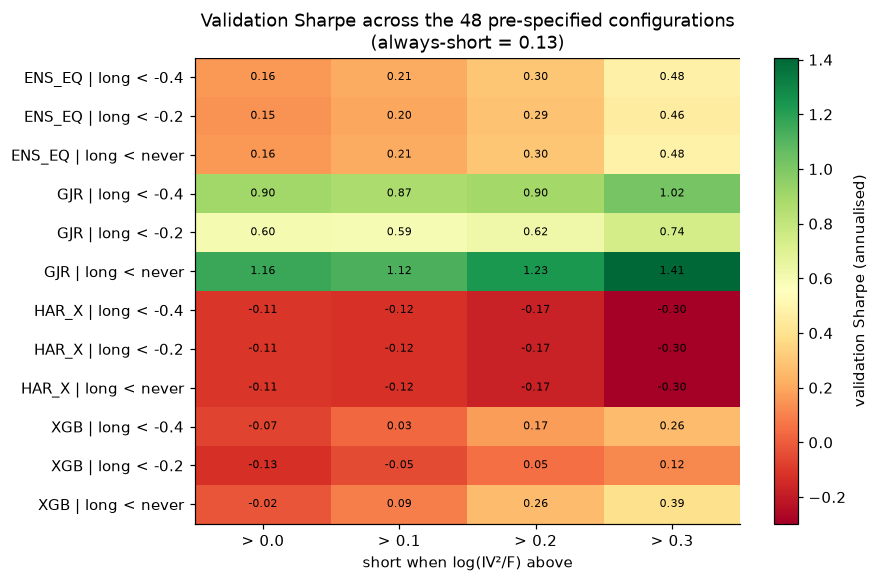

In [8]:
tv = trials.assign(long_below=trials["long_below"].astype(object).where(trials["long_below"].notna(), "never"))
pv = tv.pivot_table(index=["model", "long_below"], columns="short_above", values="sharpe_mean")
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(pv.to_numpy(dtype=float), cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(pv.shape[1]), [f"> {c}" for c in pv.columns]); ax.set_xlabel("short when log(IV²/F) above")
ax.set_yticks(range(pv.shape[0]), [f"{m} | long < {l}" for m, l in pv.index])
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax.text(j, i, f"{pv.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.axhline(-0.5, color="k"); fig.colorbar(im, ax=ax, label="validation Sharpe (annualised)")
ax.set_title(f"Validation Sharpe across the 48 pre-specified configurations\n(always-short = {always_val.summary['sharpe_mean']:.2f})")
ax.grid(False); savefig(fig, "validation_grid"); plt.show()

### D.2 How much of the validation Sharpe is selection luck? (Deflated Sharpe Ratio)

Picking the best of 48 configurations inflates its Sharpe. The DSR (Bailey & López de Prado 2014) asks how likely it is that the selected Sharpe beats the **best Sharpe that 48 skill-less strategies would produce by chance**, given the dispersion actually observed across the grid, plus non-normal returns and a short sample.

**A DSR below 0.95 means the validation result could plausibly be selection noise.** The test period is the real check.

In [9]:
sel_val = run(W[h][best.model], best.short_above, best.long_below, val_days)
po = sel_val.per_offset
n_val, sk, ku = int(po["n"].mean()), float(po["skew"].mean()), float(po["kurt"].mean())
sr_pp = best.sharpe_mean / np.sqrt(ANN)
trial_sr_pp = trials["sharpe_mean"].to_numpy() / np.sqrt(ANN)
dsr_val = S.dsr(sr_pp, n_val, sk, ku, trial_sr_pp)
psr_val = S.psr(sr_pp, n_val, sk, ku)
print(f"selected validation Sharpe {best.sharpe_mean:.2f} (per trade {sr_pp:.3f}, ~{n_val} trades per offset, "
      f"skew {sk:.2f}, kurtosis {ku:.1f})")
print(f"PSR(>0) = {psr_val:.3f} | expected best-of-{dsr_val['n_trials']} by luck (annualised) = "
      f"{dsr_val['sr_star'] * np.sqrt(ANN):.2f} | DSR = {dsr_val['dsr']:.3f}")

selected validation Sharpe 1.41 (per trade 0.396, ~49 trades per offset, skew -2.28, kurtosis 18.5)
PSR(>0) = 0.956 | expected best-of-48 by luck (annualised) = 1.00 | DSR = 0.687


### D.3 Freeze the strategy

The selected rule and both benchmarks are written to `strategy_frozen.yaml` with a hash before the test period is touched. The uncertainty-aware sizing variants are also specified here, in advance:

| Variant | Rule |
|---|---|
| **Width-scaled** | size = clip(trailing median width / today's width, 0.5, 1.5) |
| **Skip-uncertain** | no trade when today's width is above its trailing 80th percentile |

Width is log(q90/q10) from the quantile model at *h* = 20, known at *t*. The trailing window is 252 days. Width rankings are unaffected by the CQR shift from Notebook 4, so these rules need no choice between raw and conformal bands.

In [10]:
strategy_frozen = {
    "frozen_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
    "horizon": h, "implied": IVCOL[h], "base_cost_vol": SC["base_cost_vol"],
    "selected": {"model": best.model, "short_above": float(best.short_above),
                 "long_below": None if pd.isna(best.long_below) else float(best.long_below)},
    "validation_sharpe": float(best.sharpe_mean), "validation_dsr": float(dsr_val["dsr"]),
    "n_strategy_trials": int(len(trials)) + 2,          # grid + two sizing variants
    "benchmarks": ["always_short", "naive_trailing_rv (same thresholds)"],
    "sizing_variants": {"width_scaled": "clip(trailing_median_width / width, 0.5, 1.5)",
                        "skip_uncertain": "flat when width > trailing 80th percentile", "window": SC["width_window"]},
    "forecast_config_sha256": meta3["frozen_config_sha256"],
}
stext = yaml.safe_dump(strategy_frozen, sort_keys=False)
(OUT / "strategy_frozen.yaml").write_text(stext)
STRAT_HASH = hashlib.sha256(stext.encode()).hexdigest()
print(stext); print("strategy_frozen sha256:", STRAT_HASH)

frozen_utc: '2026-10-13T13:44:25+00:00'
horizon: 20
implied: vix_var
base_cost_vol: 0.005
selected:
  model: GJR
  short_above: 0.3
  long_below: null
validation_sharpe: 1.4069009820138278
validation_dsr: 0.6874071407843845
n_strategy_trials: 50
benchmarks:
- always_short
- naive_trailing_rv (same thresholds)
sizing_variants:
  width_scaled: clip(trailing_median_width / width, 0.5, 1.5)
  skip_uncertain: flat when width > trailing 80th percentile
  window: 252
forecast_config_sha256: 2d139937c8523977fa887c8fdad6f2e66cb7a9dd48a43a411cac231b0331243d

strategy_frozen sha256: 7ee4a7f52c06f18ca9084dd64f2aec22b37343f2e5081227b55c70bb043b90c5


### D.4 The test (2023–2025), run once

In [11]:
assert hashlib.sha256((OUT / "strategy_frozen.yaml").read_text().encode()).hexdigest() == STRAT_HASH
sf = yaml.safe_load((OUT / "strategy_frozen.yaml").read_text())["selected"]
sel_fc = W[h][sf["model"]]

width = np.log(W[h]["QGB_q90"] / W[h]["QGB_q10"])
med_w = width.rolling(SC["width_window"], min_periods=60).median().shift(1)
p80_w = width.rolling(SC["width_window"], min_periods=60).quantile(0.8).shift(1)
size_scaled = (med_w / width).clip(0.5, 1.5).fillna(1.0)
size_skip = (width <= p80_w).astype(float).where(p80_w.notna(), 1.0)

runs = {
    "Selected (forecast-timed)": run(sel_fc, sf["short_above"], sf["long_below"], test_days),
    "Always short": S.backtest(pd.Series(-1.0, index=test_days), SHORT_PNL.loc[test_days], EXIT.loc[test_days],
                               h, SC["base_cost_vol"], ann_periods=ANN),
    "Naive timing (trailing RV)": run(naive_fc, sf["short_above"], sf["long_below"], test_days),
    "Selected + width-scaled size": run(sel_fc, sf["short_above"], sf["long_below"], test_days, size=size_scaled),
    "Selected + skip uncertain": run(sel_fc, sf["short_above"], sf["long_below"], test_days, size=size_skip),
}
rows = []
for name, r in runs.items():
    po = r.per_offset
    sr_pp_t = r.summary["sharpe_mean"] / np.sqrt(ANN)
    rows.append({"strategy": name, **{k: r.summary[k] for k in ["sharpe_mean", "sharpe_min", "sharpe_max",
                 "mean_pnl_per_period", "hit_rate", "cvar5_per_period", "worst_trade", "max_drawdown_ladder",
                 "time_in_market", "share_short"]},
                 "sortino": float(po["sortino"].replace(np.inf, np.nan).mean()),
                 "PSR(>0)": S.psr(sr_pp_t, int(po["n"].mean()), float(po["skew"].mean()), float(po["kurt"].mean()))})
test_perf = pd.DataFrame(rows).set_index("strategy")
print("P&L in vol points per unit vega notional; Sharpe annualised; mean over 20 start offsets (min/max across offsets)")
test_perf

P&L in vol points per unit vega notional; Sharpe annualised; mean over 20 start offsets (min/max across offsets)


,sharpe_mean,sharpe_min,sharpe_max,mean_pnl_per_period,hit_rate,cvar5_per_period,worst_trade,max_drawdown_ladder,time_in_market,share_short,sortino,PSR(>0)
strategy,,,,,,,,,,,,
Selected (forecast-timed),1.922,1.279,2.683,0.01437,0.879,-0.03142,-0.1177,-0.03673,0.4801,1,7.813,0.9993
Always short,0.9337,0.3037,3.102,0.01736,0.8777,-0.2702,-0.7084,-0.4869,1,1,1.364,0.8386
Naive timing (trailing RV),2.016,0.2323,2.887,0.01857,0.8761,-0.07598,-0.3959,-0.09085,0.7128,1,4.634,0.9903
Selected + width-scaled size,1.753,1.217,2.402,0.01407,0.879,-0.03257,-0.1095,-0.04075,0.4801,1,9.519,0.9989
Selected + skip uncertain,1.595,0.8716,2.375,0.01082,0.9238,-0.01012,-0.1177,-0.02276,0.4801,1,4.975,0.9985


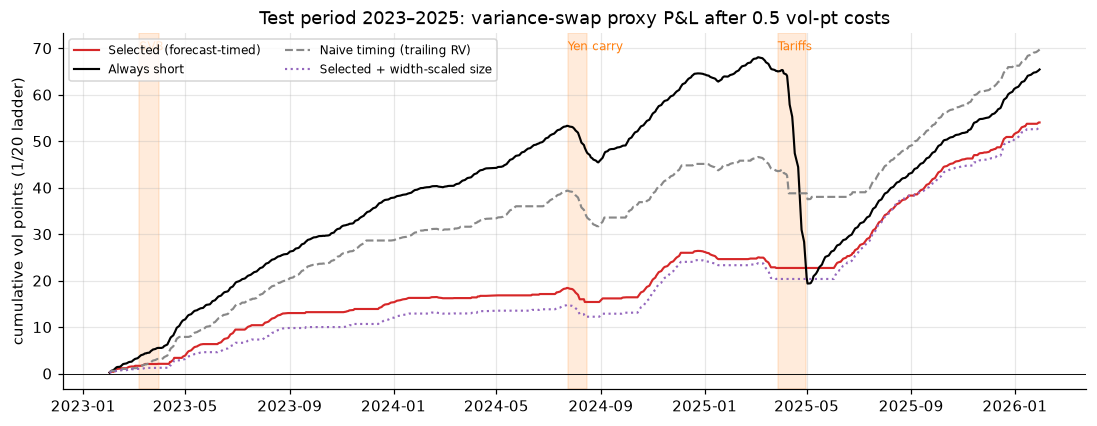

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.2))
styles = {"Selected (forecast-timed)": ("tab:red", "-"), "Always short": ("k", "-"),
          "Naive timing (trailing RV)": ("#888", "--"), "Selected + width-scaled size": ("tab:purple", ":")}
for name, (c, ls) in styles.items():
    eq = runs[name].ladder.cumsum() * 100
    ax.plot(eq.index, eq, color=c, ls=ls, lw=1.4, label=name)
for nm, (a, b) in {"SVB": ("2023-03-08", "2023-03-31"), "Yen carry": ("2024-07-24", "2024-08-16"),
                   "Tariffs": ("2025-03-28", "2025-04-30")}.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="tab:orange", alpha=0.15)
    ax.text(pd.Timestamp(a), ax.get_ylim()[1] * 0.95 if ax.get_ylim()[1] > 0 else 0, nm, fontsize=8, color="tab:orange")
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("cumulative vol points (1/20 ladder)"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Test period 2023–2025: variance-swap proxy P&L after 0.5 vol-pt costs")
savefig(fig, "test_equity"); plt.show()

### D.5 Robustness: costs, regimes, and long versus short legs

strategy,Always short,Naive timing (trailing RV),Selected (forecast-timed)
cost_vol_pts,,,
0,1.173,2.312,2.118
0.25,1.053,2.167,2.024
0.5,0.9337,2.016,1.922
1,0.6945,1.695,1.691
2,0.216,0.981,1.116


trades  mean P&L (vol)  total P&L (vol)  hit rate
leg       regime                                                   
short vol high        40         0.04751            1.901         1
          low        121          0.0142            1.719    0.7769
          mid        200         0.03593            7.187     0.915

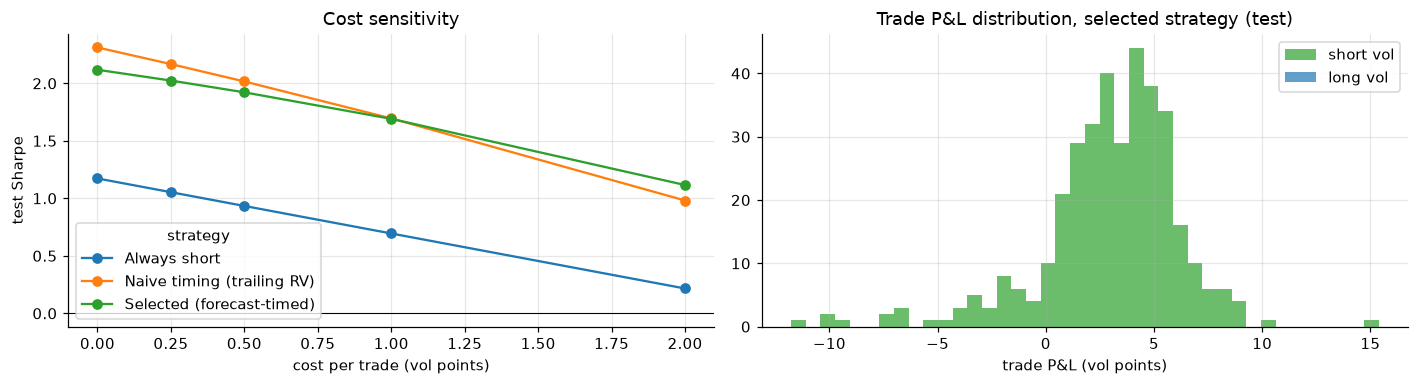

In [13]:
cost_rows = []
for c in SC["cost_grid_vol"]:
    for name, fc_ in [("Selected (forecast-timed)", sel_fc), ("Naive timing (trailing RV)", naive_fc)]:
        r = run(fc_, sf["short_above"], sf["long_below"], test_days, cost=c)
        cost_rows.append({"cost_vol_pts": 100 * c, "strategy": name, "sharpe": r.summary["sharpe_mean"]})
    r = S.backtest(pd.Series(-1.0, index=test_days), SHORT_PNL.loc[test_days], EXIT.loc[test_days], h, c, ann_periods=ANN)
    cost_rows.append({"cost_vol_pts": 100 * c, "strategy": "Always short", "sharpe": r.summary["sharpe_mean"]})
cost_sens = pd.DataFrame(cost_rows).pivot(index="cost_vol_pts", columns="strategy", values="sharpe")
display(cost_sens)

tr = runs["Selected (forecast-timed)"].trades.copy()
tr["regime"] = regimes.reindex(tr["entry"]).to_numpy()
tr["leg"] = np.select([tr.pos < 0, tr.pos > 0], ["short vol", "long vol"], "flat")
leg_tab = tr[tr.leg != "flat"].groupby(["leg", "regime"])["net"].agg(["count", "mean", "sum", lambda x: (x > 0).mean()])
leg_tab.columns = ["trades", "mean P&L (vol)", "total P&L (vol)", "hit rate"]
display(leg_tab)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
cost_sens.plot(ax=ax[0], marker="o"); ax[0].axhline(0, color="k", lw=0.7)
ax[0].set_xlabel("cost per trade (vol points)"); ax[0].set_ylabel("test Sharpe"); ax[0].set_title("Cost sensitivity")
act = tr[tr.leg != "flat"]
ax[1].hist([act.loc[act.leg == "short vol", "net"] * 100, act.loc[act.leg == "long vol", "net"] * 100],
           bins=40, label=["short vol", "long vol"], color=["tab:green", "tab:blue"], alpha=0.7, stacked=True)
ax[1].set_xlabel("trade P&L (vol points)"); ax[1].set_title("Trade P&L distribution, selected strategy (test)"); ax[1].legend()
fig.tight_layout(); savefig(fig, "robustness"); plt.show()

### D.6 Deflated Sharpe on the test period

The test Sharpe belongs to **one pre-selected strategy**, so PSR(>0) is the right single-strategy test.
- **Conservative check:** the DSR below deflates the test Sharpe for **all** trials, meaning the 48 configurations plus 2 sizing variants. This treats the test as if it had been part of the search, which is the worst case.
- **Wider multiple-testing context:** the forecasting stage ran a further 120 Optuna trials. These tuned *forecast* accuracy, not trading P&L, so they are reported but not added to the strategy trial count.

In [14]:
r_sel = runs["Selected (forecast-timed)"]
po = r_sel.per_offset
sr_t = r_sel.summary["sharpe_mean"] / np.sqrt(ANN)
dsr_test = S.dsr(sr_t, int(po["n"].mean()), float(po["skew"].mean()), float(po["kurt"].mean()),
                 np.r_[trial_sr_pp, [sr_t, sr_t]])
optuna_trials = int(yaml.safe_load((OUT / "frozen_config.yaml").read_text())["total_trials"])
print(f"test Sharpe {r_sel.summary['sharpe_mean']:.2f} | PSR(>0) {test_perf.loc['Selected (forecast-timed)', 'PSR(>0)']:.3f} | "
      f"DSR (N={dsr_test['n_trials']}) {dsr_test['dsr']:.3f} | Optuna forecast-tuning trials (context): {optuna_trials}")
d_vs_always = E.diebold_mariano(
    -runs["Selected (forecast-timed)"].trades.groupby("entry")["net"].mean(),
    -runs["Always short"].trades.groupby("entry")["net"].mean(), h)
print(f"timing vs always-short, per-entry P&L difference: DM p = {d_vs_always['p_value']:.3f} "
      f"(mean difference {100 * -d_vs_always['mean_diff']:+.2f} vol pts per trade)")

test Sharpe 1.92 | PSR(>0) 0.999 | DSR (N=50) 0.874 | Optuna forecast-tuning trials (context): 120
timing vs always-short, per-entry P&L difference: DM p = 0.805 (mean difference -0.30 vol pts per trade)


## Part E — Executable test: delta-hedged SPY straddles on historical quotes

This part runs only when a historical SPY option chain is saved at `data/raw/options/spy_chain.parquet`. It needs one row per contract per day:

| column | meaning |
|---|---|
| `date`, `expiration` | quote date and expiry |
| `strike`, `type` | strike, `C` or `P` |
| `bid`, `ask` | end-of-day quotes, used for fills |
| `iv`, `delta`, `underlying` | optional; vendor values are used when present |

**Engine (`src/options_bt.py`, unit-tested on synthetic chains):**
- Buys at the ask and sells at the bid. Picks the ATM straddle in the 30–45 DTE bucket.
- Delta-hedges with SPY daily at 0.5 bp per share traded. Cash earns the T-bill rate.
- Exits after 20 trading days, or at 5 DTE.
- Splits daily P&L into delta, gamma, vega, theta and residual.
- Flags any day where a short call might be exercised early ahead of a dividend.

The signal is the **same frozen rule** as Part D.

**The options P&L is in dollars per straddle.** It is reported alongside the proxy, not merged with it.

In [15]:
chain_path = ROOT / SC["options"]["chain_path"]
OPTIONS_RESULTS = None
if chain_path.exists():
    oc = SC["options"]
    chain = pd.read_parquet(chain_path)
    print(f"chain: {len(chain):,} rows, {chain['date'].nunique()} days, {pd.to_datetime(chain['date']).min().date()} -> "
          f"{pd.to_datetime(chain['date']).max().date()}")
    by_date = O.prepare_chain(chain)
    spot = panel["close_raw"]                                 # options reference the unadjusted price
    sig_all = S.positions(np.log(IV / sel_fc.reindex(IV.index)), sf["short_above"], sf["long_below"])
    res = {}
    for split, days in [("val", val_days), ("test", test_days)]:
        trades_o, daily_o, flags_o = O.run_straddle_backtest(
            by_date, spot, panel["rate"], sig_all.reindex(days).fillna(0.0), div_yield=oc["div_yield"],
            dte_range=tuple(oc["dte_range"]), dte_target=oc["dte_target"], hold_days=oc["hold_days"],
            min_dte_exit=oc["min_dte_exit"], hedge_cost_bps=oc["hedge_cost_bps"], dividends=panel["dividend"])
        res[split] = (trades_o, daily_o, flags_o)
        if len(trades_o):
            att = daily_o[["delta_pnl", "gamma_pnl", "vega_pnl", "theta_pnl", "residual", "hedge_pnl"]].sum()
            print(f"\n{split}: {len(trades_o)} trades | total ${trades_o.pnl.sum():,.0f} per 1-lot | "
                  f"mean {trades_o.pnl_per_premium.mean():+.1%} of premium | spread paid ${trades_o.spread_cost.sum():,.0f} | "
                  f"flags {len(flags_o)}")
            display(att.to_frame(f"{split} P&L attribution ($)").T)
            display(trades_o.groupby("side")[["pnl", "pnl_per_premium"]].agg(["count", "mean", "sum"]))
    OPTIONS_RESULTS = res
    if len(res["test"][0]):
        res["test"][0].to_csv(RES / "options_test_trades.csv", index=False)
        res["test"][1].to_csv(RES / "options_test_attribution.csv", index=False)
else:
    print(f"No option chain at {chain_path.relative_to(ROOT)}.\n"
          "Part E is skipped. The variance-swap proxy in Part D stands as the H5 evidence, with its caveats.\n"
          "To run it: save a historical SPY EOD chain (2019–2025) in the format above and rerun this notebook.")

No option chain at data\raw\options\spy_chain.parquet.
Part E is skipped. The variance-swap proxy in Part D stands as the H5 evidence, with its caveats.
To run it: save a historical SPY EOD chain (2019–2025) in the format above and rerun this notebook.


## Verdicts and project summary (H1–H5)

In [16]:
def holm_p(h, split, mdl):
    return float(h3[(h3.horizon == h) & (h3.split == split) & (h3.model == mdl)]["p_f_holm"].iloc[0])

v = {}
r3 = h3[(h3.horizon == HS) & (h3.split == "test") & (h3.model == "XGB")].iloc[0]
v["H3"] = (f"{'SUPPORTED' if (r3.b_f > 0 and holm_p(HS, 'test', 'XGB') < 0.05) else 'NOT SUPPORTED'}: "
           f"b_F = {r3.b_f:.2f}, Holm p = {holm_p(HS, 'test', 'XGB'):.3f} (XGB, h={HS}, test)")
r4 = h4[(h4.horizon == HS) & (h4.split == "test") & (h4.model == "XGB")].iloc[0]
if r4.R2_ci_lo > 0 and r4.R2n_ci_lo > 0:
    h4_lab = "SUPPORTED (model adds beyond naive)"
elif r4.R2_ci_lo > 0:
    h4_lab = "PARTIAL: VRP predictable, but not better than the naive IV² − trailing RV"
else:
    h4_lab = "NOT SUPPORTED"
v["H4"] = (f"{h4_lab}: R2_OOS vs hist. mean = {r4.R2_OOS:.3f} [{r4.R2_ci_lo:.3f}, {r4.R2_ci_hi:.3f}]; "
           f"vs naive = {r4.R2_vs_naive:.3f} [{r4.R2n_ci_lo:.3f}, {r4.R2n_ci_hi:.3f}] (XGB, h={HS}, test)")
psr_sel = test_perf.loc["Selected (forecast-timed)", "PSR(>0)"]
beats_always = test_perf.loc["Selected (forecast-timed)", "sharpe_mean"] > test_perf.loc["Always short", "sharpe_mean"]
timing_adds = beats_always and d_vs_always["p_value"] < 0.05
if psr_sel > 0.95 and dsr_test["dsr"] > 0.95 and timing_adds:
    h5_lab = "SUPPORTED: positive after costs AND timing beats always-short"
elif psr_sel > 0.95:
    h5_lab = "PREMIUM ONLY: positive Sharpe after costs, but no evidence the forecast improves on always-short"
else:
    h5_lab = "NOT SUPPORTED"
v["H5"] = (f"{h5_lab}: "
           f"test Sharpe {test_perf.loc['Selected (forecast-timed)', 'sharpe_mean']:.2f}, PSR {psr_sel:.2f}, DSR {dsr_test['dsr']:.2f}; "
           f"{'beats' if beats_always else 'does not beat'} always-short "
           f"({test_perf.loc['Always short', 'sharpe_mean']:.2f}; DM p = {d_vs_always['p_value']:.2f}). Proxy, not executable.")

nb4 = pd.read_csv(RES / "verdicts_h1_h2.csv", index_col=0)
summary = pd.Series({"H1 (h=5)": nb4.loc[5, "H1"], "H1 (h=20)": nb4.loc[20, "H1"],
                     "H2 (h=5)": nb4.loc[5, "H2"], "H2 (h=20)": nb4.loc[20, "H2"], **v}, name="verdict")
with pd.option_context("display.max_colwidth", 200):
    display(summary.to_frame())

,verdict
H1 (h=5),NOT SUPPORTED: no significant difference between XGB and HAR-X
H1 (h=20),NOT SUPPORTED: no significant difference between XGB and HAR-X
H2 (h=5),NOT SUPPORTED: same ordering in every regime (joint p = 0.703)
H2 (h=20),"NOT SUPPORTED: point estimates change sign across regimes, but jointly insignificant (p = 0.195)"
H3,"SUPPORTED: b_F = 0.40, Holm p = 0.004 (XGB, h=20, test)"
H4,"NOT SUPPORTED: R2_OOS vs hist. mean = -0.175 [-0.667, 0.430]; vs naive = 0.353 [-0.755, 0.843] (XGB, h=20, test)"
H5,"PREMIUM ONLY: positive Sharpe after costs, but no evidence the forecast improves on always-short: test Sharpe 1.92, PSR 1.00, DSR 0.87; beats always-short (0.93; DM p = 0.80). Proxy, not executable."


## Save outputs

In [17]:
vrp_summary.to_csv(RES / "vrp_summary_dev.csv")
h3.to_csv(RES / "h3_encompassing.csv", index=False)
h4.to_csv(RES / "h4_vrp_predictability.csv", index=False)
trials.to_csv(RES / "strategy_validation_trials.csv", index=False)
test_perf.to_csv(RES / "strategy_performance.csv")
cost_sens.to_csv(RES / "strategy_cost_sensitivity.csv")
leg_tab.to_csv(RES / "strategy_legs_by_regime.csv")
summary.to_csv(RES / "verdicts_all.csv")
findings = {"strategy_frozen_sha256": STRAT_HASH[:16], "selected": sf,
            "val_sharpe": round(float(best.sharpe_mean), 2), "val_dsr": round(float(dsr_val["dsr"]), 3),
            "test_sharpe": round(float(test_perf.loc["Selected (forecast-timed)", "sharpe_mean"]), 2),
            "test_sharpe_always_short": round(float(test_perf.loc["Always short", "sharpe_mean"]), 2),
            "test_psr": round(float(psr_sel), 3), "test_dsr": round(float(dsr_test["dsr"]), 3),
            "timing_vs_always_short_DM_p": round(float(d_vs_always["p_value"]), 3),
            "options_backtest_run": OPTIONS_RESULTS is not None, **{k: str(x) for k, x in summary.items()}}
(OUT / "nb05_findings.json").write_text(json.dumps(findings, indent=2, default=str))
pd.Series(findings, name="value").to_frame()

,value
strategy_frozen_sha256,7ee4a7f52c06f18c
selected,"{'model': 'GJR', 'short_above': 0.3, 'long_bel..."
val_sharpe,1.41
val_dsr,0.687
test_sharpe,1.92
test_sharpe_always_short,0.93
test_psr,0.999
test_dsr,0.874
timing_vs_always_short_DM_p,0.805
options_backtest_run,False


**How to write this up (report Sections 8–11):**

1. **VRP facts first (Part A).** Report the size, sign, persistence and fat left tail. This is the economic backdrop: option buyers pay for crash insurance.
2. **H3 is the bridge between the two halves of the project.** If b<sub>F</sub> is not significant, the market already prices what the models know. In that case no forecast-based option trade *should* work, and H5 failing is the expected consequence, not a disappointment.
3. **H5: lead with the always-short benchmark.** Most of any short-volatility Sharpe is the unconditional premium. The research contribution is whether timing improves on it, measured by the DM test on per-trade P&L. Quote PSR and DSR, the worst trade, and the tariff-shock drawdown.
4. **State the proxy caveat plainly.** It covers SPX vs SPY, no convexity adjustment, and assumed costs. Part E is the executable version and is ready for real quotes.
5. **Limitations:**
   - three test years, which means about 37 independent 20-day trades per offset
   - one asset
   - daily data rather than intraday realised variance